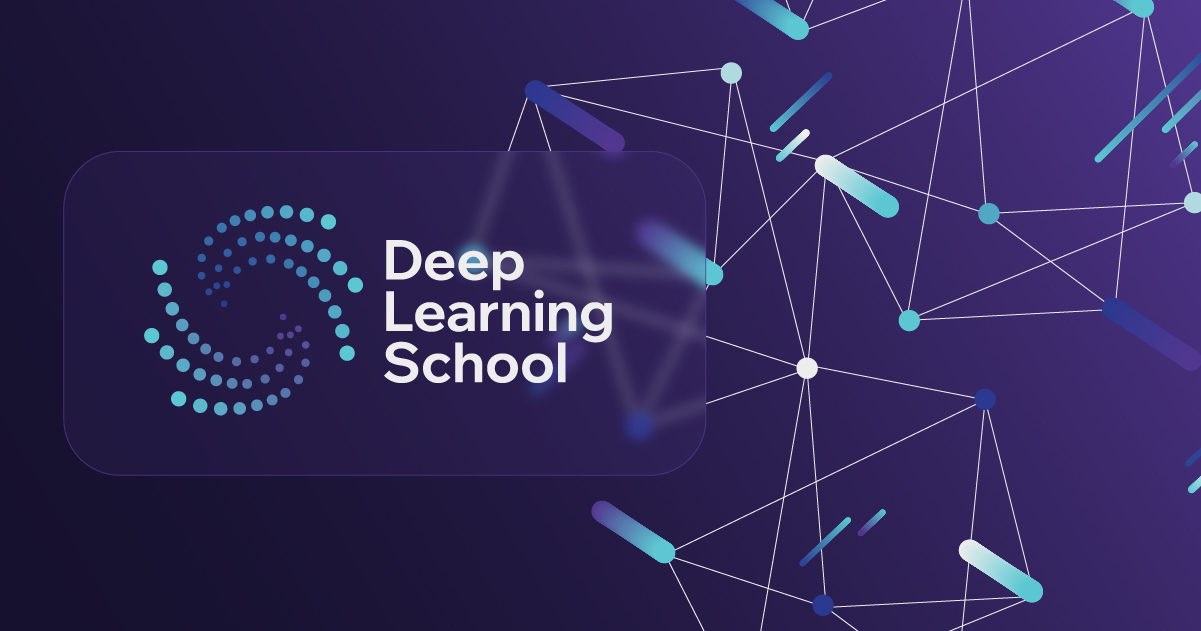

<h3 style="text-align: center;"><b>Школа глубокого обучения ФПМИ МФТИ</b></h3>

<h1 style="text-align: center;"><b>Домашнее задание. Обучение языковой модели с помощью LSTM </b></h1>


В этом задании Вам предстоит обучить языковую модель с помощью рекуррентной нейронной сети. В отличие от семинарского занятия, Вам необходимо будет работать с отдельными словами, а не буквами.


Установим модуль ```datasets```, чтобы нам проще было работать с данными.

In [1]:
!pip install datasets

Импорт необходимых библиотек

In [2]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

import numpy as np
import matplotlib.pyplot as plt

from tqdm.auto import tqdm
from datasets import load_dataset
from nltk.tokenize import sent_tokenize, word_tokenize
from sklearn.model_selection import train_test_split
import nltk

from collections import Counter
from typing import List

import seaborn
seaborn.set(palette='summer')

In [3]:
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


True

In [4]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
device

'cuda'

## Подготовка данных

Воспользуемся датасетом imdb. В нем хранятся отзывы о фильмах с сайта imdb. Загрузим данные с помощью функции ```load_dataset```

In [5]:
# Загрузим датасет
dataset = load_dataset('stanfordnlp/imdb')

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/unsupervised-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 42.0MB            

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

### Препроцессинг данных и создание словаря (1 балл)

Далее вам необходмо самостоятельно произвести препроцессинг данных и получить словарь или же просто ```set``` строк. Что необходимо сделать:

1. Разделить отдельные тренировочные примеры на отдельные предложения с помощью функции ```sent_tokenize``` из бибилиотеки ```nltk```. Каждое отдельное предложение будет одним тренировочным примером.
2. Оставить только те предложения, в которых меньше ```word_threshold``` слов.
3. Посчитать частоту вхождения каждого слова в оставшихся предложениях. Для деления предлоения на отдельные слова удобно использовать функцию ```word_tokenize```.
4. Создать объект ```vocab``` класса ```set```, положить в него служебные токены '\<unk\>', '\<bos\>', '\<eos\>', '\<pad\>' и vocab_size самых частовстречающихся слов.   

In [6]:
train_data = dataset.data['train']['text'].to_pylist()

In [7]:
sentences = []
word_threshold = 32

all_words = []
for text in tqdm(train_data):
    for sent in sent_tokenize(text):
        words = word_tokenize(sent)
        if len(words) <  word_threshold:
            sentences.append(sent)
            all_words+=words
# Получить отдельные предложения и поместить их в sentences

  0%|          | 0/25000 [00:00<?, ?it/s]

In [8]:
print("Всего предложений:", len(sentences))

Всего предложений: 198801


Посчитаем для каждого слова его встречаемость.

In [9]:
words = Counter(all_words)

# Расчет встречаемости слов
words.most_common(10)

[('.', 170189),
 ('the', 126124),
 (',', 114121),
 ('a', 71655),
 ('and', 68621),
 ('of', 62048),
 ('to', 59630),
 ('is', 56695),
 ('I', 46474),
 ('it', 39499)]

Добавим в словарь ```vocab_size``` самых встречающихся слов.

In [10]:
vocab = set()
vocab_size = 40000

# Наполнение словаря
for word, _ in words.most_common()[:vocab_size]:
    vocab.add(word)

vocab = vocab.union({'<unk>', '<bos>', '<eos>', '<pad>'})

In [11]:
assert '<unk>' in vocab
assert '<bos>' in vocab
assert '<eos>' in vocab
assert '<pad>' in vocab
assert len(vocab) == vocab_size + 4

In [12]:
print("Всего слов в словаре:", len(vocab))

Всего слов в словаре: 40004


### Подготовка датасета (1 балл)

Далее, как и в семинарском занятии, подготовим датасеты и даталоадеры.

В классе ```WordDataset``` вам необходимо реализовать метод ```__getitem__```, который будет возвращать сэмпл данных по входному idx, то есть список целых чисел (индексов слов).

Внутри этого метода необходимо добавить служебные токены начала и конца последовательности, а также токенизировать соответствующее предложение с помощью ```word_tokenize``` и сопоставить ему индексы из ```word2ind```.

In [13]:
word2ind = {char: i for i, char in enumerate(vocab)}
ind2word = {i: char for char, i in word2ind.items()}

In [14]:
class WordDataset:
    def __init__(self, sentences):
        self.data = sentences
        self.unk_id = word2ind['<unk>']
        self.bos_id = word2ind['<bos>']
        self.eos_id = word2ind['<eos>']
        self.pad_id = word2ind['<pad>']

    def __getitem__(self, idx: int) -> List[int]:
        tokenized_sentence = []
        # Допишите код здесь
        words = word_tokenize(self.data[idx])
        tokenized_sentence.append(self.bos_id)
        for word in words:
            tokenized_sentence.append(word2ind.get(word, self.unk_id))
        tokenized_sentence.append(self.eos_id)

        return tokenized_sentence

    def __len__(self) -> int:
        return len(self.data)

In [15]:
def collate_fn_with_padding(
    input_batch: List[List[int]], pad_id=word2ind['<pad>']) -> torch.Tensor:
    seq_lens = [len(x) for x in input_batch]
    max_seq_len = max(seq_lens)

    new_batch = []
    for sequence in input_batch:
        for _ in range(max_seq_len - len(sequence)):
            sequence.append(pad_id)
        new_batch.append(sequence)

    sequences = torch.LongTensor(new_batch).to(device)

    new_batch = {
        'input_ids': sequences[:,:-1],
        'target_ids': sequences[:,1:]
    }

    return new_batch

In [16]:
train_sentences, temp_sentences = train_test_split(sentences, test_size=0.2, random_state=42)
eval_sentences, test_sentences = train_test_split(temp_sentences, test_size=0.5, random_state=42)

train_dataset = WordDataset(train_sentences)
eval_dataset = WordDataset(eval_sentences)
test_dataset = WordDataset(test_sentences)

batch_size = 128

train_dataloader = DataLoader(
    train_dataset, collate_fn=collate_fn_with_padding, batch_size=batch_size)

eval_dataloader = DataLoader(
    eval_dataset, collate_fn=collate_fn_with_padding, batch_size=batch_size)

test_dataloader = DataLoader(
    test_dataset, collate_fn=collate_fn_with_padding, batch_size=batch_size)

## Обучение и архитектура модели

Вам необходимо на практике проверить, что влияет на качество языковых моделей. В этом задании нужно провести серию экспериментов с различными вариантами языковых моделей и сравнить различия в конечной перплексии на тестовом множестве.

Возмоэные идеи для экспериментов:

* Различные RNN-блоки, например, LSTM или GRU. Также можно добавить сразу несколько RNN блоков друг над другом с помощью аргумента num_layers. Вам поможет официальная документация [здесь](https://pytorch.org/docs/stable/generated/torch.nn.LSTM.html)
* Различные размеры скрытого состояния. Различное количество линейных слоев после RNN-блока. Различные функции активации.
* Добавление нормализаций в виде Dropout, BatchNorm или LayerNorm
* Различные аргументы для оптимизации, например, подбор оптимального learning rate или тип алгоритма оптимизации SGD, Adam, RMSProp и другие
* Любые другие идеи и подходы

После проведения экспериментов необходимо составить таблицу результатов, в которой описан каждый эксперимент и посчитана перплексия на тестовом множестве.

Учтите, что эксперименты, которые различаются, например, только размером скрытого состояния или количеством линейных слоев считаются, как один эксперимент.

Успехов!

### Функция evaluate (1 балл)

Заполните функцию ```evaluate```

In [17]:
def evaluate(model, criterion, dataloader) -> float:
    model.eval()
    perplexity = []
    with torch.no_grad():
        for batch in dataloader:
            logits, _ = model(batch['input_ids'])    # Посчитайте логиты предсказаний следующих слов
            loss = criterion(logits.flatten(start_dim = 0, end_dim = 1),
                batch['target_ids'].flatten())
            perplexity.append(torch.exp(loss).item())

    perplexity = sum(perplexity) / len(perplexity)

    return perplexity

### Train loop (1 балл)

Напишите функцию для обучения модели.

In [18]:
def train_model(model: nn.Module, optimizer, criterion, num_epochs: int = 5):
    losses = []
    perplexities = []
    for epoch in range(num_epochs):
        model.train()
        epoch_losses = []
        for i, batch in enumerate(tqdm(train_dataloader, desc=f'Training epoch {epoch+1}:')):
            optimizer.zero_grad()
            logits, _ = model(batch['input_ids'])
            loss = criterion(logits.flatten(start_dim = 0, end_dim = 1),
                batch['target_ids'].flatten())
            loss.backward()
            optimizer.step()
            epoch_losses.append(loss.item())
        losses.append(sum(epoch_losses) / len(epoch_losses))
        perplexities.append(evaluate(model, criterion, train_dataloader))
    return losses, perplexities

## Сразу напишу небольшой код для тестирования вывода модели
Выбираем по методу top_k и можем при желании регулировать температуру модели: чем она ниже, тем более вероятные токены будут выбираться чаще.

In [79]:
def take_next_token(logits, temperature = 1, top_k = 10):
    logits = logits[0, -1, :]
    tops, top_idxs = torch.topk(logits, top_k)
    aligned = tops/temperature
    probs = torch.softmax(aligned, dim = -1)
    return top_idxs[torch.multinomial(probs, num_samples=1).item()].item()

def generate_text(model, start_text, length=100, temperature=1, top_k = 10):
    model.eval()
    with torch.no_grad():
        input_ids = torch.tensor([word2ind.get(c, word2ind['<unk>']) for c in word_tokenize(start_text)], dtype=torch.long, device=device)
        output, hidden = model(input_ids.unsqueeze(0))
        next_id = take_next_token(output, temperature=temperature, top_k=top_k)
        output_text = [ind2word[next_id]]
        for _ in range(length-1):
            output, hidden = model(torch.tensor([[next_id]], dtype = torch.long, device = device), hidden)
            next_id = take_next_token(output, temperature=temperature, top_k=top_k)
            output_text.append(ind2word[next_id])
            if next_id == word2ind.get('<eos>', -1):
                break
        return " ".join(output_text)

### Первый эксперимент (2 балла)

Определите архитектуру модели и обучите её.

In [19]:
class LanguageModel(nn.Module):
    def __init__(self, vocab_size: int, hidden_dim: int = 256, rnn_layers: int = 1, rnn_layer_type: str = 'RNN', dropout: float = 0.1):
        super().__init__()
        # Опишите свою нейронную сеть здесь
        self.embedding = nn.Embedding(vocab_size, hidden_dim)
        match rnn_layer_type:
            case 'RNN':
                self.rnn = nn.RNN(hidden_dim, hidden_dim, batch_first=True, num_layers=rnn_layers, dropout=dropout if rnn_layers > 1 else 0)
            case 'GRU':
                self.rnn = nn.GRU(hidden_dim, hidden_dim, batch_first=True, num_layers=rnn_layers, dropout=dropout if rnn_layers > 1 else 0)
            case 'LSTM':
                self.rnn = nn.LSTM(hidden_dim, hidden_dim, batch_first=True, num_layers=rnn_layers, dropout=dropout if rnn_layers > 1 else 0)
            case _:
                raise ValueError("Invalid rnn layer")
        self.linear = nn.Linear(hidden_dim, hidden_dim)
        self.non_lin = nn.Tanh()
        self.projection = nn.Linear(hidden_dim, vocab_size)


    def forward(self, input_batch: torch.Tensor, hidden = None) -> torch.Tensor:
        x = self.embedding(input_batch)
        x, hidden = self.rnn(x,hidden)
        x = self.projection(self.non_lin(self.linear(x)))
        return x, hidden


In [92]:
model = LanguageModel(vocab_size=len(vocab)).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
criterion = nn.CrossEntropyLoss(ignore_index=word2ind['<pad>'])

In [93]:
loss, perplexity = train_model(model, optimizer, criterion, num_epochs = 10)

Training epoch 1::   0%|          | 0/1243 [00:00<?, ?it/s]

Training epoch 2::   0%|          | 0/1243 [00:00<?, ?it/s]

Training epoch 3::   0%|          | 0/1243 [00:00<?, ?it/s]

Training epoch 4::   0%|          | 0/1243 [00:00<?, ?it/s]

Training epoch 5::   0%|          | 0/1243 [00:00<?, ?it/s]

Training epoch 6::   0%|          | 0/1243 [00:00<?, ?it/s]

Training epoch 7::   0%|          | 0/1243 [00:00<?, ?it/s]

Training epoch 8::   0%|          | 0/1243 [00:00<?, ?it/s]

Training epoch 9::   0%|          | 0/1243 [00:00<?, ?it/s]

Training epoch 10::   0%|          | 0/1243 [00:00<?, ?it/s]

### Построим графики по loss и perplexity

Text(0.5, 1.0, 'perplexity')

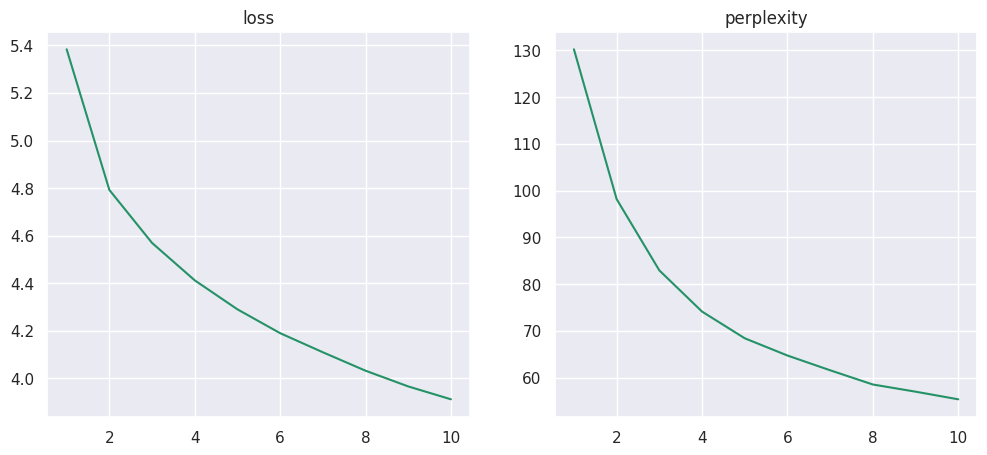

In [94]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].plot(range(1, len(loss)+1), loss)
axes[0].set_title("loss")
axes[1].plot(range(1, len(perplexity)+1), perplexity)
axes[1].set_title("perplexity")

In [95]:
print(f"loss: {loss[-1]}, perplexity: {perplexity[-1]}")

loss: 3.912241940908823, perplexity: 55.375246525194406


Perplexity кажется достаточно большим

### Попробуем что-нибудь сгенерировать

In [86]:
generate_text(model, "he Terminator is", top_k=1)

"n't sure he 's the only person who can do . <eos>"

In [84]:
for _ in range(10):
    print(generate_text(model, "The Terminator is", top_k = 10))

a good one . <eos>
n't a good movie . <eos>
one of the funniest films of all time . <eos>
a <unk> <unk> for anyone who 's ever been on , but I 'll be a huge fan of the genre . <eos>
not all worth seeing . <eos>
the movie that I have ever seen , like the whole thing is to be made . <eos>
seen of the original , but it 's the only thing that is the case . <eos>
the first thing that I can only imagine the director who had been involved at the end . <eos>
a movie for me but it was an extremely satisfying film . <eos>
seen of a good movie . <eos>


Что-то связанное c отзывами генерируется неплохо

### Второй эксперимент (2 балла)

Попробуйте что-то поменять в модели или в пайплайне обучения, идеи для экспериментов можно подсмотреть выше.

Training epoch 1::   0%|          | 0/1243 [00:00<?, ?it/s]

Training epoch 2::   0%|          | 0/1243 [00:00<?, ?it/s]

Training epoch 3::   0%|          | 0/1243 [00:00<?, ?it/s]

Training epoch 4::   0%|          | 0/1243 [00:00<?, ?it/s]

Training epoch 5::   0%|          | 0/1243 [00:00<?, ?it/s]

...

Training epoch 7::   0%|          | 0/1243 [00:00<?, ?it/s]

Training epoch 8::   0%|          | 0/1243 [00:00<?, ?it/s]

Training epoch 9::   0%|          | 0/1243 [00:00<?, ?it/s]

Training epoch 10::   0%|          | 0/1243 [00:00<?, ?it/s]

loss: 3.733945638828477, perplexity: 46.135249187748755


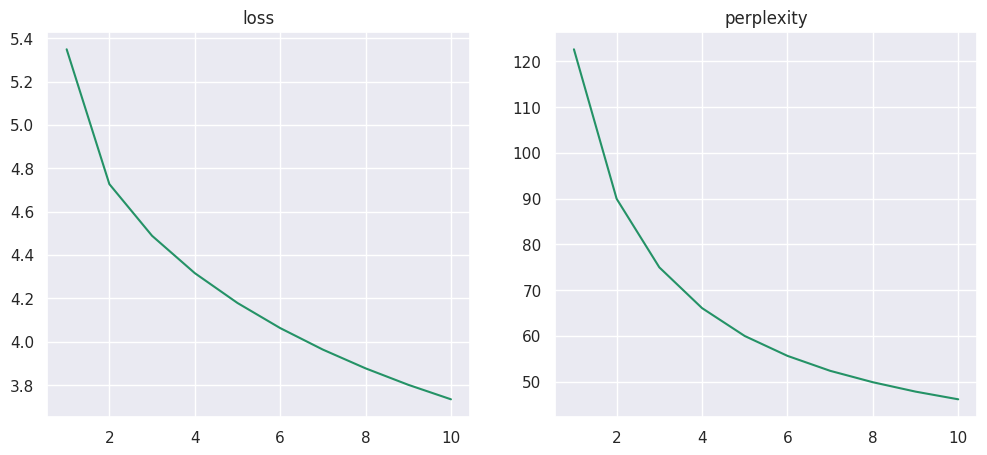

In [96]:
model = LanguageModel(vocab_size=len(vocab), rnn_layer_type='GRU').to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
criterion = nn.CrossEntropyLoss(ignore_index=word2ind['<pad>'])
loss, perplexity = train_model(model, optimizer, criterion, num_epochs = 10)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].plot(range(1, len(loss)+1), loss)
axes[0].set_title("loss")
axes[1].plot(range(1, len(perplexity)+1), perplexity)
axes[1].set_title("perplexity")
print(f"loss: {loss[-1]}, perplexity: {perplexity[-1]}")

loss и perplexity неплохо уменьшились, GRU c более сложной архетиктурой лучше усваивает закономерности

Попробуем взять два GRU слоя

Training epoch 1::   0%|          | 0/1243 [00:00<?, ?it/s]

Training epoch 2::   0%|          | 0/1243 [00:00<?, ?it/s]

Training epoch 3::   0%|          | 0/1243 [00:00<?, ?it/s]

Training epoch 4::   0%|          | 0/1243 [00:00<?, ?it/s]

Training epoch 5::   0%|          | 0/1243 [00:00<?, ?it/s]

...

Training epoch 7::   0%|          | 0/1243 [00:00<?, ?it/s]

Training epoch 8::   0%|          | 0/1243 [00:00<?, ?it/s]

Training epoch 9::   0%|          | 0/1243 [00:00<?, ?it/s]

Training epoch 10::   0%|          | 0/1243 [00:00<?, ?it/s]

loss: 3.941809104703073, perplexity: 51.29394520355249


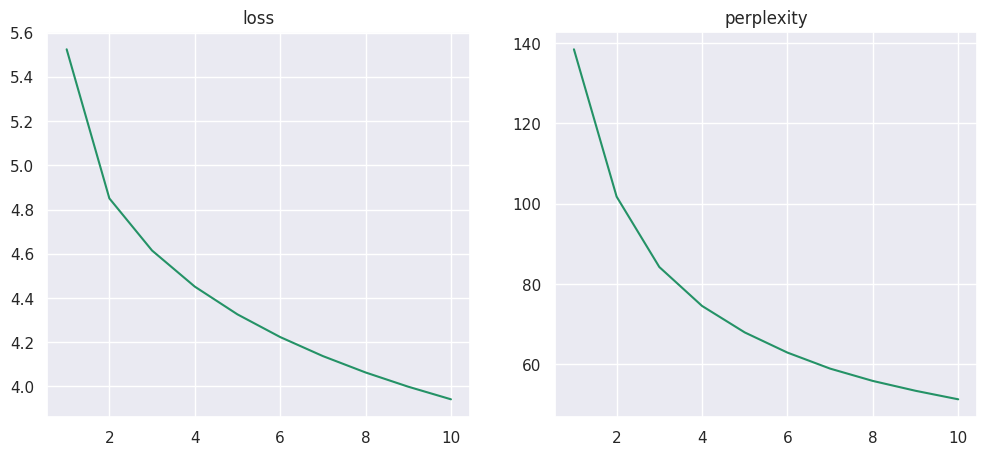

In [97]:
model = LanguageModel(vocab_size=len(vocab), rnn_layer_type='GRU', rnn_layers=2).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
criterion = nn.CrossEntropyLoss(ignore_index=word2ind['<pad>'])
loss, perplexity = train_model(model, optimizer, criterion, num_epochs = 10)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].plot(range(1, len(loss)+1), loss)
axes[0].set_title("loss")
axes[1].plot(range(1, len(perplexity)+1), perplexity)
axes[1].set_title("perplexity")
print(f"loss: {loss[-1]}, perplexity: {perplexity[-1]}")

Качество ухудшилось, вероятно модели нужно больше времени чтобы обучится, попробуем 20 эпох

Training epoch 1::   0%|          | 0/1243 [00:00<?, ?it/s]

Training epoch 2::   0%|          | 0/1243 [00:00<?, ?it/s]

Training epoch 3::   0%|          | 0/1243 [00:00<?, ?it/s]

Training epoch 4::   0%|          | 0/1243 [00:00<?, ?it/s]

Training epoch 5::   0%|          | 0/1243 [00:00<?, ?it/s]

...

Training epoch 17::   0%|          | 0/1243 [00:00<?, ?it/s]

Training epoch 18::   0%|          | 0/1243 [00:00<?, ?it/s]

Training epoch 19::   0%|          | 0/1243 [00:00<?, ?it/s]

Training epoch 20::   0%|          | 0/1243 [00:00<?, ?it/s]

loss: 3.57504257308027, perplexity: 37.480494550611354


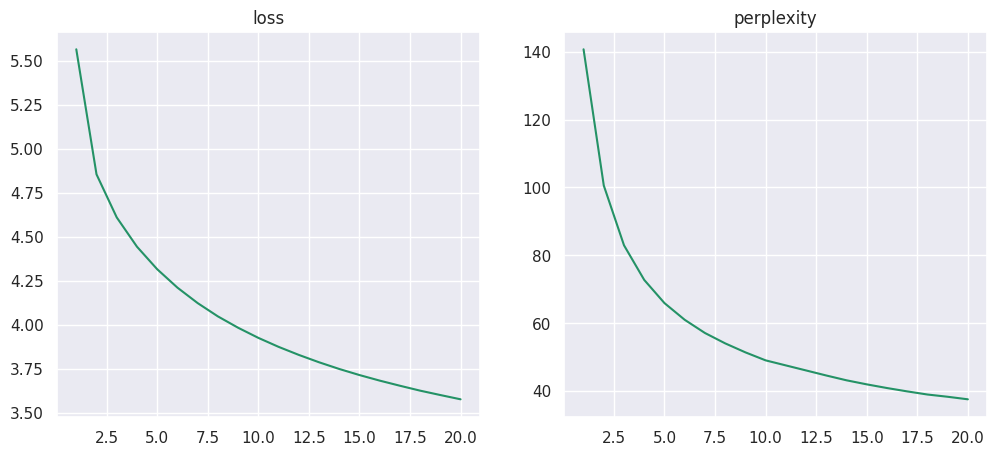

In [98]:
model = LanguageModel(vocab_size=len(vocab), rnn_layer_type='GRU', rnn_layers=2).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
criterion = nn.CrossEntropyLoss(ignore_index=word2ind['<pad>'])
loss, perplexity = train_model(model, optimizer, criterion, num_epochs = 20)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].plot(range(1, len(loss)+1), loss)
axes[0].set_title("loss")
axes[1].plot(range(1, len(perplexity)+1), perplexity)
axes[1].set_title("perplexity")
print(f"loss: {loss[-1]}, perplexity: {perplexity[-1]}")

Благодаря большему количеству эпох два слоя GRU смогли достичь лучшего результата, perplexity показывает что теперь модель явно более увеена в своих предсказаниях чем раньше.

### Отчет (2 балла)

Опишите проведенные эксперименты. Сравните перплексии полученных моделей. Предложите идеи по улучшению качества моделей.